# 07.5: Greeks

## Theta

An option's value is **intrinsic value + time value**. Holding the underlying price and other inputs constant, a long option generally loses time value as expiry approaches. **Theta** measures this sensitivity to the passage of time, so it is almost always negative for a long option:

$$\Theta = \frac{\partial V}{\partial t} = -\frac{\partial V}{\partial \tau},$$

where $t$ is calendar time and $\tau$ is time remaining to expiry. At expiry, only intrinsic value remains.

The plots below use a European call with strike 100, volatility 20%, and zero interest and dividend rates to isolate time decay.

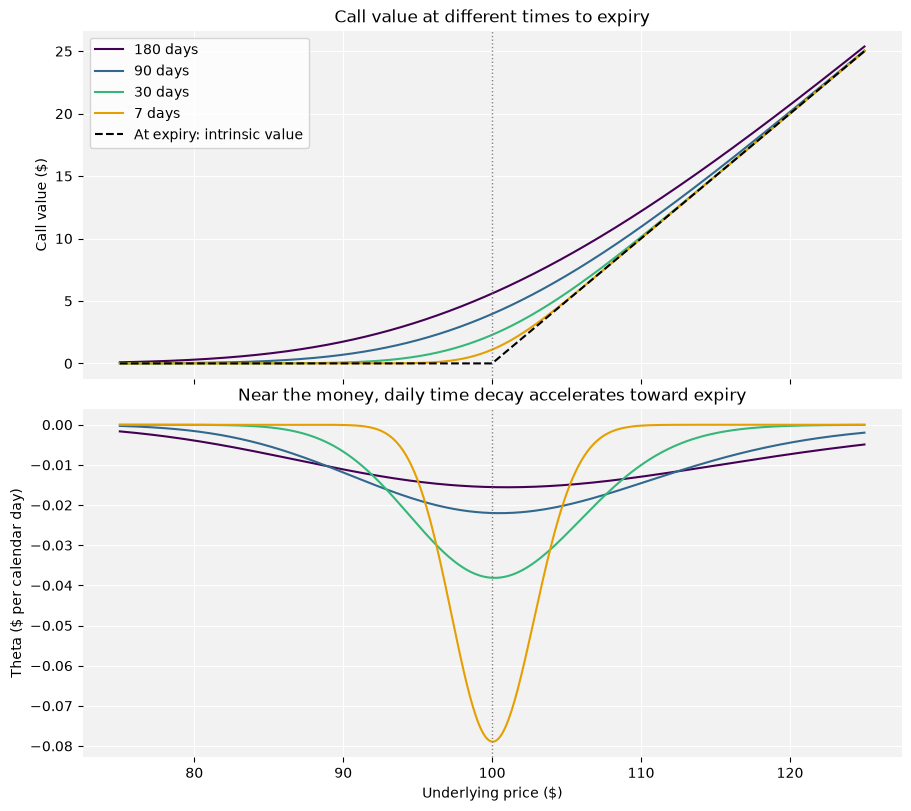

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

strike = 100
volatility = 0.20
underlying = np.linspace(75, 125, 501)
expiry_days = [180, 90, 30, 7]
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

fig, (price_ax, theta_ax) = plt.subplots(
    2, 1, sharex=True, figsize=(9, 8), layout="constrained"
)
for days, color in zip(expiry_days, colors):
    tau = days / 365
    d1 = (np.log(underlying / strike) + 0.5 * volatility**2 * tau) / (
        volatility * np.sqrt(tau)
    )
    d2 = d1 - volatility * np.sqrt(tau)
    call = underlying * norm.cdf(d1) - strike * norm.cdf(d2)
    theta_per_day = -underlying * norm.pdf(d1) * volatility / (2 * np.sqrt(tau)) / 365
    price_ax.plot(underlying, call, color=color, label=f"{days} days")
    theta_ax.plot(underlying, theta_per_day, color=color)

price_ax.plot(
    underlying,
    np.maximum(underlying - strike, 0),
    color="black",
    linestyle="--",
    label="At expiry: intrinsic value",
)
price_ax.set(title="Call value at different times to expiry", ylabel="Call value ($)")
price_ax.legend()
theta_ax.set(
    title="Near the money, daily time decay accelerates toward expiry",
    xlabel="Underlying price ($)",
    ylabel="Theta ($ per calendar day)",
)
for ax in (price_ax, theta_ax):
    ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

The gap between each call-price curve and the dashed intrinsic-value line is **time value**. It is greatest near the money and shrinks as expiry approaches. For ITM/OTM options theta tends to zero in expiry. For ATM options theta tends to infinity. 

Near the money, **the magnitude of theta increases as expiry approaches**: theta becomes more negative, so time value disappears faster per day. Away from the money, theta instead tends toward zero near expiry as the outcome becomes more certain.

“Almost always” matters: interest rates and dividends can make theta positive in some cases, such as certain deep-in-the-money European puts. The plots use zero rates and dividends, where long vanilla options have negative theta before expiry.

## Vega

**Vega** measures how an option's theoretical value changes with implied volatility:

$$\text{Vega} = \frac{\partial V}{\partial \sigma}.$$

For a long option, vega is almost always positive. Greater implied volatility means more scope for favourable underlying moves, while the buyer's loss remains limited to the premium. With the underlying price fixed, intrinsic value is unchanged, so the option gains **time value**. Standard European calls and puts have positive vega before expiry.

Below, the strike is fixed at 100 and time to expiry at 90 days, with zero interest and dividend rates. Each curve shows call value against the underlying price at a different implied volatility.

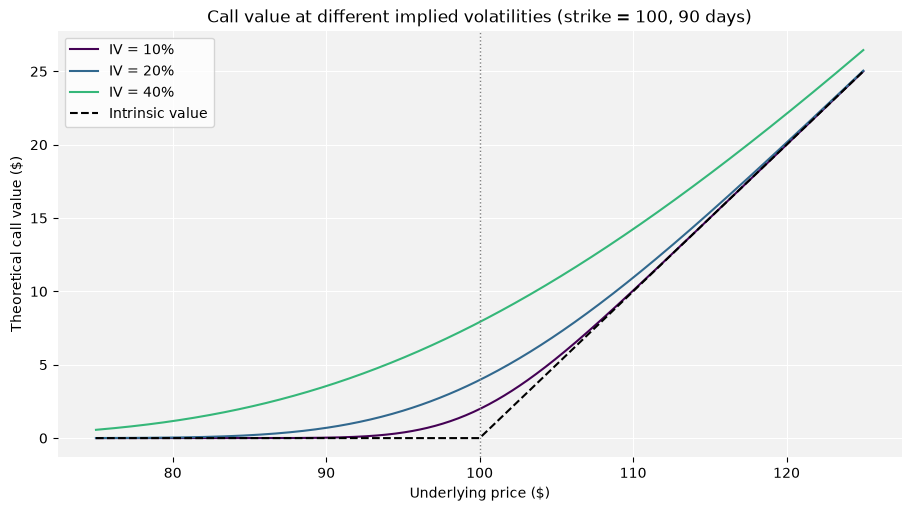

In [2]:
vega_strike = 100
vega_tau = 90 / 365
vega_underlying = np.linspace(75, 125, 501)
volatilities = [0.10, 0.20, 0.40]
vega_colors = ["#440154", "#31688e", "#35b779"]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for sigma, color in zip(volatilities, vega_colors):
    d1 = (np.log(vega_underlying / vega_strike) + 0.5 * sigma**2 * vega_tau) / (
        sigma * np.sqrt(vega_tau)
    )
    d2 = d1 - sigma * np.sqrt(vega_tau)
    call_values = vega_underlying * norm.cdf(d1) - vega_strike * norm.cdf(d2)
    ax.plot(vega_underlying, call_values, color=color, label=f"IV = {sigma:.0%}")
ax.plot(
    vega_underlying,
    np.maximum(vega_underlying - vega_strike, 0),
    color="black",
    linestyle="--",
    label="Intrinsic value",
)
ax.axvline(vega_strike, color="grey", linestyle=":", linewidth=1)
ax.set(
    title="Call value at different implied volatilities (strike = 100, 90 days)",
    xlabel="Underlying price ($)",
    ylabel="Theoretical call value ($)",
)
ax.set_facecolor("#f2f2f2")
ax.grid(color="white")
ax.set_axisbelow(True)
ax.legend()
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

At any given underlying price, higher implied volatility raises the call's theoretical value by adding **time value**. The vertical gap between curves shows this effect. Vega measures sensitivity to volatility and is commonly quoted per **one percentage point** increase, such as 20% to 21%.

## Interpreting risk

- **Positive delta:** We want the underlying to rise.
- **Negative delta:** We want the underlying to fall.
- **Positive gamma:** Delta adjusts in our favour as the underlying moves, amplifying gains and cushioning losses relative to what our starting delta predicts. For example, a long call's delta increases as the underlying rises and decreases as it falls.
- **Negative gamma:** Delta adjusts against us as the underlying moves, amplifying losses and limiting gains relative to our starting delta. A delta-neutral trader who is short options generally wants the underlying to stay relatively still, allowing time decay to work in their favour.

**Together, delta and gamma tell us the preferred direction and size of market moves.** Delta tells us which direction helps; gamma tells us whether larger moves help or hurt relative to that delta exposure. To judge how quickly a move needs to happen, we also need **theta**, the cost or benefit of time passing. Even a slow move can hurt a negative-gamma position if it is large enough.

**The signs of gamma and theta are almost always opposite.** Positive gamma means the trader wants price movements; negative theta means that, for every day without a price movement, the option loses value, holding other factors constant. So the trader also wants enough price movement to offset this time decay. This intuition is clearest for a delta-hedged position: time decay still applies on days when the underlying moves.

### Gamma and vega

One might think that positive gamma means we want price movements and therefore must be long vega too. However, **gamma gives exposure to realised price movements**, while **vega gives exposure to changes in implied volatility**. Realised and implied volatility are related, but they are not the same: the underlying can move substantially without implied volatility rising, and implied volatility can rise even when the underlying barely moves.

A long vanilla option has both positive gamma and positive vega, but a portfolio combining options at different strikes or expiries need not. Being long gamma therefore does not necessarily mean being long vega.